# Walmart Store Sales Forecasting & Inventory Intelligence

## Project Overview

This project analyzes Walmart weekly sales at the **Store–Department–Week** level and develops time-aware sales forecasting models. The workflow combines PostgreSQL data access, exploratory data analysis, historical sales features, machine learning, and seasonal analysis.

### Business questions
- How do sales vary by week, month, store type, and department?
- How do sales behave around major holidays?
- Can historical sales improve weekly sales forecasts?
- Which model performs best on a future validation period?

### Dataset
The project uses the Walmart Recruiting Store Sales Forecasting dataset. The training data contains store, department, date, weekly sales, and holiday indicator fields. The dataset does **not** contain actual inventory, stockout, replenishment, or lost-sales records. Inventory recommendations must therefore be described as potential applications, not measured inventory outcomes.

### Forecasting setup
- Training period: dates before January 1, 2012.
- Validation period: dates on or after January 1, 2012.
- Validation is chronological rather than random.
- Historical features are shifted within each Store–Department series to avoid using the current target as a feature.
- The validation design represents **rolling one-week-ahead forecasting with actual prior-week sales available**. It is not a recursive multi-week forecast.

### Evaluation metrics
- **MAE:** average absolute prediction error, in dollars.
- **RMSE:** square root of average squared prediction error, in dollars. RMSE penalizes large errors more strongly.

> Run the notebook from top to bottom after restarting the kernel. Keep your PostgreSQL database available and enter your password when prompted.


## Imports and Required Libraries


In [ ]:

import pandas as pd
import psycopg2
import numpy as np
import matplotlib.pyplot as plt



## Connect to PostgreSQL


In [ ]:
# Connect to PostgreSQL securely
from getpass import getpass

conn = psycopg2.connect(
    host="localhost",
    database="walmart_sales",
    user="vasudhapandhare",
    password=getpass("PostgreSQL password: "),
    port=5432
)

print("Connected to PostgreSQL successfully!")


## Load Walmart Training Data


In [ ]:
# Load Walmart training data from PostgreSQL
query = "SELECT * FROM train;"

df = pd.read_sql_query(query, conn)
df["Date"] = pd.to_datetime(df["Date"])

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


/var/folders/nl/w9g5lm9578s_6p8xpc6g_ph00000gn/T/ipykernel_19948/90716099.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, conn)


Dataset loaded successfully!
Shape: (421570, 5)


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


## Inspect Dataset Structure


In [ ]:

# Basic dataset inspection

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (421570, 5)

Column names:
['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday']

Data types:
Store                    int64
Dept                     int64
Date            datetime64[us]
Weekly_Sales           float64
IsHoliday                 bool
dtype: object

Missing values:
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

Duplicate rows: 0


## Check Data Quality and Date Coverage


In [ ]:

# Check missing values and date range

print("Missing values:")
print(df.isnull().sum())

print("\nDate range:")
print("Start:", df["Date"].min())
print("End:", df["Date"].max())

print("\nUnique stores:", df["Store"].nunique())
print("Unique departments:", df["Dept"].nunique())


Missing values:
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

Date range:
Start: 2010-02-05 00:00:00
End: 2012-10-26 00:00:00

Unique stores: 45
Unique departments: 81


## Convert Dates and Create Calendar Features


In [ ]:

# Convert Date column to datetime

df["Date"] = pd.to_datetime(df["Date"])

# Extract useful date features
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Week"] = df["Date"].dt.isocalendar().week

print("Date conversion completed!")
print("Date type:", df["Date"].dtype)

df[["Date", "Year", "Month", "Week"]].head()


Date conversion completed!
Date type: datetime64[us]


,Date,Year,Month,Week
0,2010-02-05,2010,2,5
1,2010-02-12,2010,2,6
2,2010-02-19,2010,2,7
3,2010-02-26,2010,2,8
4,2010-03-05,2010,3,9


## Plot Weekly Sales Trends


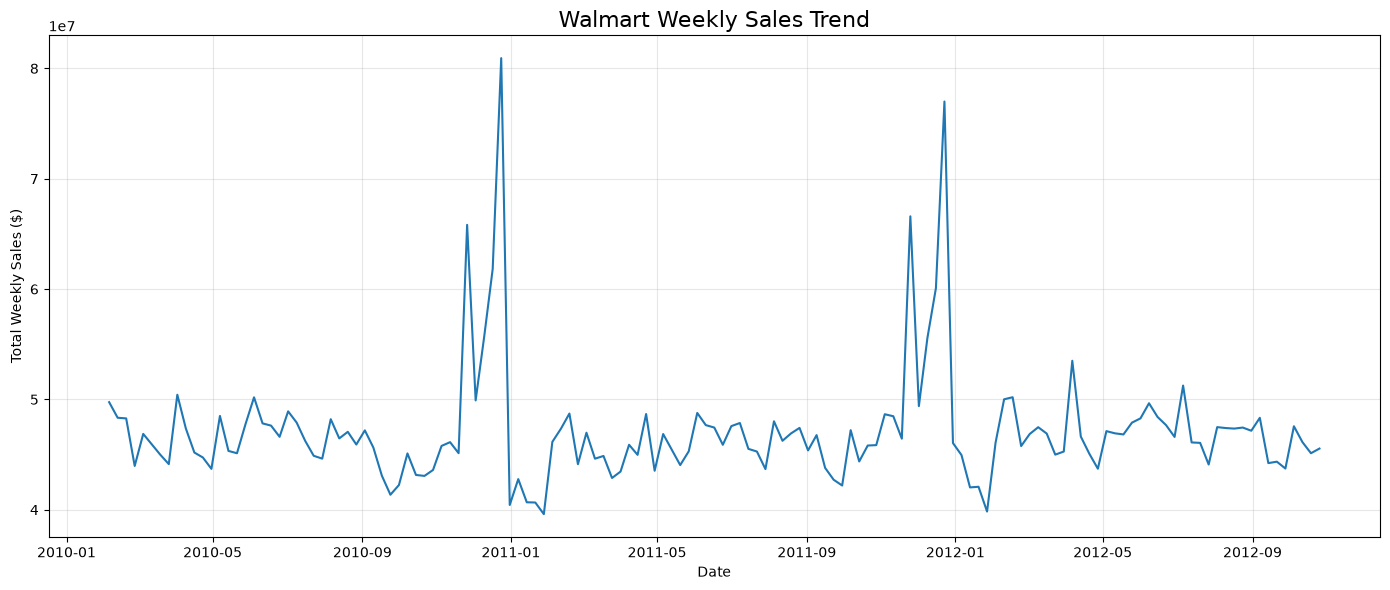

In [ ]:

import matplotlib.pyplot as plt

# Aggregate sales by date
weekly_sales = df.groupby("Date")["Weekly_Sales"].sum().reset_index()

# Plot sales trend
plt.figure(figsize=(14, 6))

plt.plot(
    weekly_sales["Date"],
    weekly_sales["Weekly_Sales"]
)

plt.title("Walmart Weekly Sales Trend", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales ($)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Analyze Monthly Sales


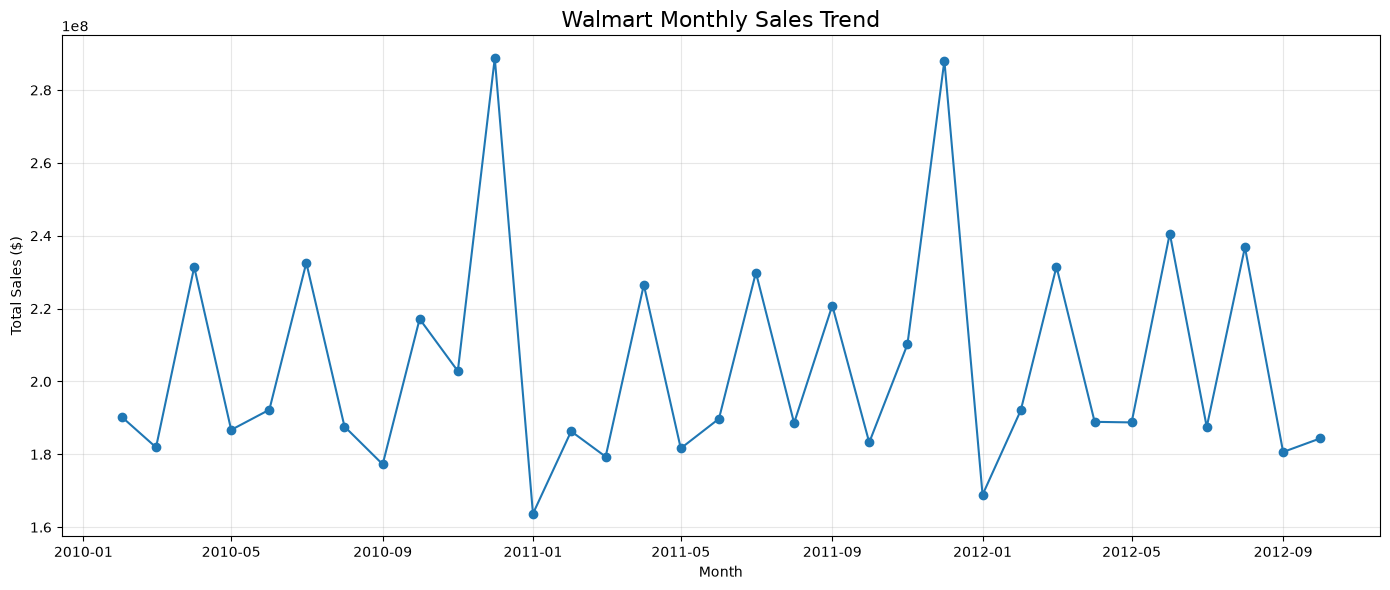

In [ ]:

# Aggregate sales by month

monthly_sales = (
    df.groupby(["Year", "Month"])["Weekly_Sales"]
    .sum()
    .reset_index()
)

# Create a date column for plotting
monthly_sales["Date"] = pd.to_datetime(
    monthly_sales["Year"].astype(str)
    + "-"
    + monthly_sales["Month"].astype(str)
    + "-01"
)

# Plot monthly sales
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Date"],
    monthly_sales["Weekly_Sales"],
    marker="o"
)

plt.title("Walmart Monthly Sales Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Compare Holiday and Non-Holiday Sales


   IsHoliday  Weekly_Sales     Category
0      False  15901.445069  Non-Holiday
1       True  17035.823187      Holiday


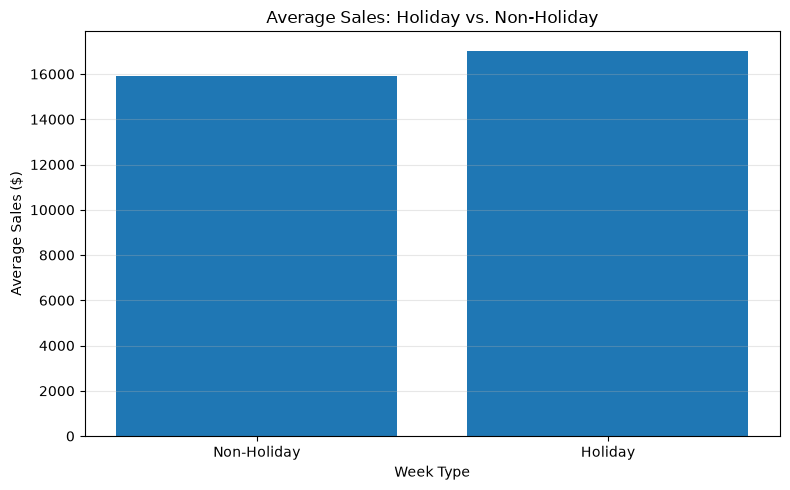

In [ ]:

# Compare holiday and non-holiday sales

holiday_sales = (
    df.groupby("IsHoliday")["Weekly_Sales"]
    .mean()
    .reset_index()
)

holiday_sales["Category"] = holiday_sales["IsHoliday"].map({
    True: "Holiday",
    False: "Non-Holiday"
})

print(holiday_sales)

# Visualize the comparison
plt.figure(figsize=(8, 5))

plt.bar(
    holiday_sales["Category"],
    holiday_sales["Weekly_Sales"]
)

plt.title("Average Sales: Holiday vs. Non-Holiday")
plt.xlabel("Week Type")
plt.ylabel("Average Sales ($)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## Analyze Sales by Store Type


  Type  Weekly_Sales
0    A  20099.568043
1    B  12237.075977
2    C   9519.532538


/var/folders/nl/w9g5lm9578s_6p8xpc6g_ph00000gn/T/ipykernel_19948/1403914605.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  stores_df = pd.read_sql_query(


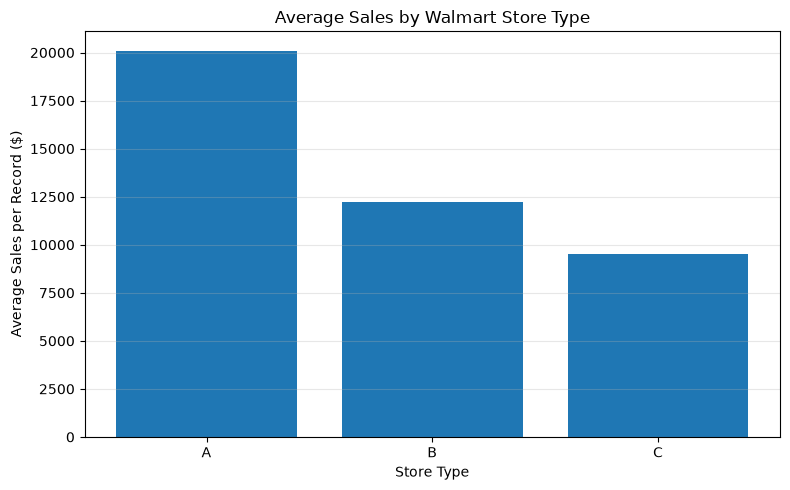

In [ ]:

# Store type analysis

# Load store information from PostgreSQL
stores_df = pd.read_sql_query(
    'SELECT * FROM stores;',
    conn
)

# Merge store information with sales data
store_data = df.merge(
    stores_df,
    on="Store",
    how="left"
)

# Calculate sales by store type
store_type_sales = (
    store_data.groupby("Type")["Weekly_Sales"]
    .mean()
    .reset_index()
    .sort_values("Weekly_Sales", ascending=False)
)

print(store_type_sales)

# Visualize average sales by store type
plt.figure(figsize=(8, 5))

plt.bar(
    store_type_sales["Type"],
    store_type_sales["Weekly_Sales"]
)

plt.title("Average Sales by Walmart Store Type")
plt.xlabel("Store Type")
plt.ylabel("Average Sales per Record ($)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## Analyze Department-Level Sales


    Dept  Weekly_Sales
73    92  75204.870531
76    95  69824.423080
36    38  61090.619568
60    72  50566.515417
57    65  45441.706224
71    90  45232.084488
38    40  44900.702727
1      2  43607.020113
72    91  33687.910758
75    94  33405.883963


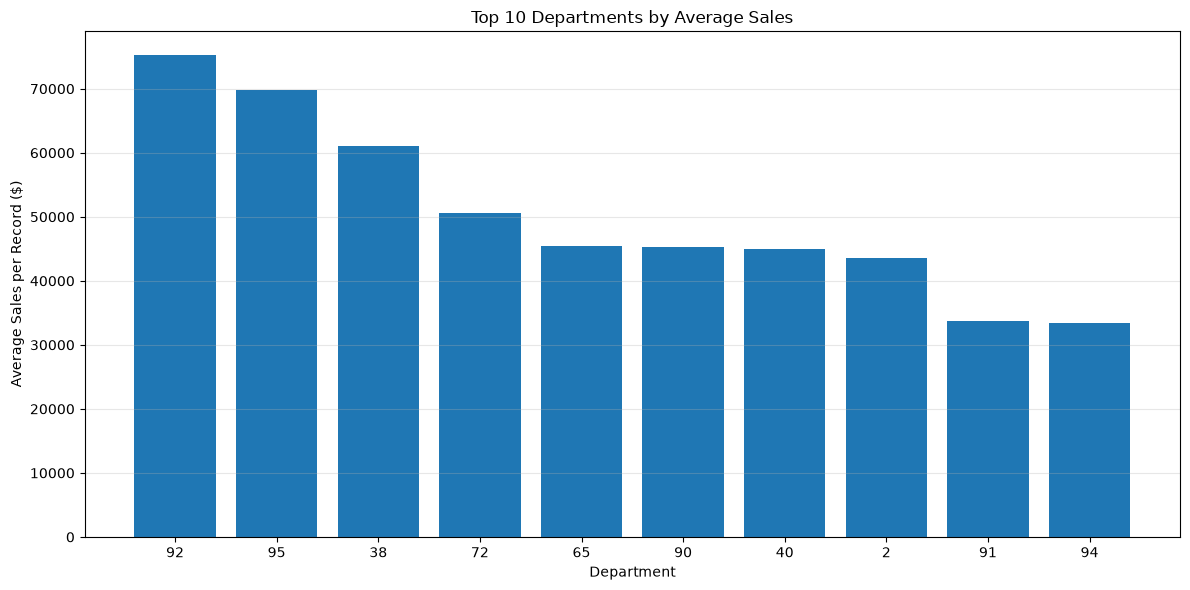

In [ ]:

# Analyze average sales by department

department_sales = (
    df.groupby("Dept")["Weekly_Sales"]
    .mean()
    .reset_index()
    .sort_values("Weekly_Sales", ascending=False)
)

# Display top 10 departments
top_departments = department_sales.head(10)

print(top_departments)

# Visualize top 10 departments
plt.figure(figsize=(12, 6))

plt.bar(
    top_departments["Dept"].astype(str),
    top_departments["Weekly_Sales"]
)

plt.title("Top 10 Departments by Average Sales")
plt.xlabel("Department")
plt.ylabel("Average Sales per Record ($)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## Compare Weekly Sales Patterns Across Years


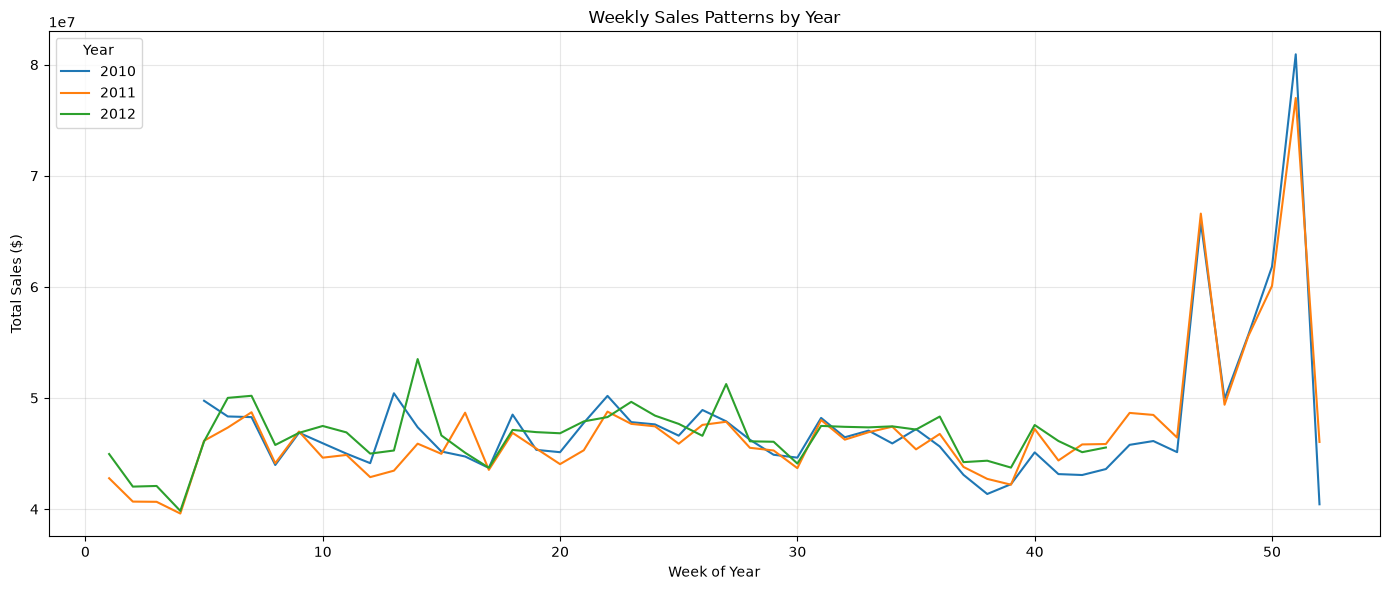

In [ ]:

# Analyze sales by year and week

yearly_weekly_sales = (
    df.groupby(["Year", "Week"])["Weekly_Sales"]
    .sum()
    .reset_index()
)

# Plot yearly weekly sales
plt.figure(figsize=(14, 6))

for year in sorted(yearly_weekly_sales["Year"].unique()):
    year_data = yearly_weekly_sales[
        yearly_weekly_sales["Year"] == year
    ]

    plt.plot(
        year_data["Week"],
        year_data["Weekly_Sales"],
        label=str(year)
    )

plt.title("Weekly Sales Patterns by Year")
plt.xlabel("Week of Year")
plt.ylabel("Total Sales ($)")
plt.legend(title="Year")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 1. Forecasting Data Preparation

The earlier EDA cells inspect sales trends, holiday differences, store types, departments, and weekly patterns. This section prepares the data for model development.

We sort each Store–Department series by date, create calendar features, and convert the holiday flag to an integer for model compatibility.

In [ ]:
# Prepare data for forecasting

df = df.sort_values(["Store", "Dept", "Date"]).reset_index(drop=True).copy()
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Week"] = df["Date"].dt.isocalendar().week.astype(int)
df["IsHoliday"] = df["IsHoliday"].astype(int)

print("Rows:", len(df))
print("Date range:", df["Date"].min(), "to", df["Date"].max())
display(df.head())


Rows: 421570
Date range: 2010-02-05 00:00:00 to 2012-10-26 00:00:00


,Store,Dept,Date,Weekly_Sales,IsHoliday,Year,Month,Week
0,1,1,2010-02-05,24924.50,0,2010,2,5
1,1,1,2010-02-12,46039.49,1,2010,2,6
2,1,1,2010-02-19,41595.55,0,2010,2,7
3,1,1,2010-02-26,19403.54,0,2010,2,8
4,1,1,2010-03-05,21827.90,0,2010,3,9


## 2. Time-Based Train–Validation Split

A chronological split simulates forecasting future weeks using earlier data. We use records before 2012 for training and records from 2012 onward for validation.

This is a single holdout period. For a stronger final evaluation, a later version of the project can add rolling-origin backtesting across multiple cutoffs.

In [ ]:
# Split chronologically

train_raw = df[df["Date"] < pd.Timestamp("2012-01-01")].copy()
validation_raw = df[df["Date"] >= pd.Timestamp("2012-01-01")].copy()

print("Training rows:", len(train_raw))
print("Training dates:", train_raw["Date"].min(), "to", train_raw["Date"].max())
print("Validation rows:", len(validation_raw))
print("Validation dates:", validation_raw["Date"].min(), "to", validation_raw["Date"].max())


Training rows: 294132
Training dates: 2010-02-05 00:00:00 to 2011-12-30 00:00:00
Validation rows: 127438
Validation dates: 2012-01-06 00:00:00 to 2012-10-26 00:00:00


## 3. Seasonal Naive Baseline

The seasonal naive model predicts a Store–Department's sales using its sales from exactly 52 weeks earlier. This provides a useful benchmark because Walmart sales show recurring annual patterns.

We will later evaluate this baseline on the **same validation rows** used by the machine-learning models, so the comparison is fair.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create a 52-week seasonal prediction from training-period records
seasonal_source = train_raw[["Store", "Dept", "Date", "Weekly_Sales"]].copy()
seasonal_source = seasonal_source.rename(columns={
    "Date": "Seasonal_Date",
    "Weekly_Sales": "Seasonal_Prediction"
})

seasonal_validation = validation_raw[["Store", "Dept", "Date", "Weekly_Sales"]].copy()
seasonal_validation["Seasonal_Date"] = seasonal_validation["Date"] - pd.Timedelta(weeks=52)
seasonal_validation = seasonal_validation.merge(
    seasonal_source,
    on=["Store", "Dept", "Seasonal_Date"],
    how="left"
)

seasonal_available = seasonal_validation.dropna(subset=["Seasonal_Prediction"]).copy()
seasonal_mae = mean_absolute_error(
    seasonal_available["Weekly_Sales"], seasonal_available["Seasonal_Prediction"]
)
seasonal_rmse = np.sqrt(mean_squared_error(
    seasonal_available["Weekly_Sales"], seasonal_available["Seasonal_Prediction"]
))

print("Seasonal naive MAE:", f"${seasonal_mae:,.2f}")
print("Seasonal naive RMSE:", f"${seasonal_rmse:,.2f}")
print("Rows with seasonal predictions:", len(seasonal_available))


Seasonal naive MAE: $1,811.56
Seasonal naive RMSE: $3,835.58
Rows with seasonal predictions: 123905


## 4. Create Historical Sales Features

The following features capture recent and annual sales patterns for each Store–Department combination:

- `Sales_Lag_1`: sales from the previous observed week.
- `Sales_Lag_4`: sales from four observations earlier.
- `Sales_Lag_52`: sales from approximately one year earlier.
- `Sales_Rolling_4`: mean sales over the previous four observations.
- `Sales_Rolling_12`: mean sales over the previous twelve observations.

Rolling averages use `shift(1)` so the current week's target is excluded. Rows without enough history are removed from model training and validation.

In [ ]:
# Create lag and rolling features within each Store-Department series

grouped_sales = df.groupby(["Store", "Dept"])["Weekly_Sales"]
df["Sales_Lag_1"] = grouped_sales.shift(1)
df["Sales_Lag_4"] = grouped_sales.shift(4)
df["Sales_Lag_52"] = grouped_sales.shift(52)
df["Sales_Rolling_4"] = grouped_sales.transform(lambda s: s.shift(1).rolling(4).mean())
df["Sales_Rolling_12"] = grouped_sales.transform(lambda s: s.shift(1).rolling(12).mean())

features = [
    "Store", "Dept", "Month", "Week", "IsHoliday",
    "Sales_Lag_1", "Sales_Lag_4", "Sales_Lag_52",
    "Sales_Rolling_4", "Sales_Rolling_12"
]

model_df = df.dropna(subset=features).copy()
train_df = model_df[model_df["Date"] < pd.Timestamp("2012-01-01")].copy()
validation_df = model_df[model_df["Date"] >= pd.Timestamp("2012-01-01")].copy()

X_train = train_df[features]
y_train = train_df["Weekly_Sales"]
X_val = validation_df[features]
y_val = validation_df["Weekly_Sales"]

print("Training rows after lag feature creation:", len(train_df))
print("Validation rows after lag feature creation:", len(validation_df))
print("Training dates:", train_df["Date"].min(), "to", train_df["Date"].max())
print("Validation dates:", validation_df["Date"].min(), "to", validation_df["Date"].max())
display(df[["Store", "Dept", "Date", "Weekly_Sales"] + features[5:]].head(12))


Training rows after lag feature creation: 136342
Validation rows after lag feature creation: 124741
Training dates: 2011-02-04 00:00:00 to 2011-12-30 00:00:00
Validation dates: 2012-01-06 00:00:00 to 2012-10-26 00:00:00


,Store,Dept,Date,Weekly_Sales,Sales_Lag_1,Sales_Lag_4,Sales_Lag_52,Sales_Rolling_4,Sales_Rolling_12
0,1,1,2010-02-05,24924.50,NaN,NaN,NaN,NaN,NaN
1,1,1,2010-02-12,46039.49,24924.50,NaN,NaN,NaN,NaN
2,1,1,2010-02-19,41595.55,46039.49,NaN,NaN,NaN,NaN
3,1,1,2010-02-26,19403.54,41595.55,NaN,NaN,NaN,NaN
4,1,1,2010-03-05,21827.90,19403.54,24924.50,NaN,32990.7700,NaN
5,1,1,2010-03-12,21043.39,21827.90,46039.49,NaN,32216.6200,NaN
6,1,1,2010-03-19,22136.64,21043.39,41595.55,NaN,25967.5950,NaN
7,1,1,2010-03-26,26229.21,22136.64,19403.54,NaN,21102.8675,NaN
8,1,1,2010-04-02,57258.43,26229.21,21827.90,NaN,22809.2850,NaN
9,1,1,2010-04-09,42960.91,57258.43,21043.39,NaN,31666.9175,NaN


## 5. Train Random Forest

Random Forest is a tree-based ensemble model. We use a fixed random seed so results are reproducible.

The model is evaluated on the chronological validation set. Since the validation features include actual sales from prior weeks, this is a rolling one-week-ahead evaluation.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_val)

rf_mae = mean_absolute_error(y_val, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_predictions))

print("Random Forest with historical features")
print(f"MAE: ${rf_mae:,.2f}")
print(f"RMSE: ${rf_rmse:,.2f}")


Random Forest with historical features
MAE: $1,382.13
RMSE: $3,087.93


## 6. Train LightGBM

LightGBM is a gradient-boosted tree model. We train it on the same features and rows as Random Forest for a direct comparison.

In [ ]:
from lightgbm import LGBMRegressor

lgb_model = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=10,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)
lgb_model.fit(X_train, y_train)
lgb_predictions = lgb_model.predict(X_val)

lgb_mae = mean_absolute_error(y_val, lgb_predictions)
lgb_rmse = np.sqrt(mean_squared_error(y_val, lgb_predictions))

print("LightGBM with historical features")
print(f"MAE: ${lgb_mae:,.2f}")
print(f"RMSE: ${lgb_rmse:,.2f}")


LightGBM with historical features
MAE: $1,467.10
RMSE: $3,342.22


## 7. Compare Models on the Same Validation Rows

To make a fair comparison, evaluate the seasonal naive baseline on the same validation rows available to the historical-feature models. The seasonal baseline may not have a matching record for every row, so the comparison below uses the intersection of rows with a seasonal prediction.

The MAE and RMSE values are in dollars. Lower values indicate smaller prediction errors.

In [ ]:
# Build one common evaluation table
comparison_rows = validation_df[["Store", "Dept", "Date", "Weekly_Sales"]].copy()
comparison_rows["RF_Prediction"] = rf_predictions
comparison_rows["LightGBM_Prediction"] = lgb_predictions
comparison_rows["Seasonal_Date"] = comparison_rows["Date"] - pd.Timedelta(weeks=52)

comparison_rows = comparison_rows.merge(
    seasonal_source,
    on=["Store", "Dept", "Seasonal_Date"],
    how="left"
)
common_eval = comparison_rows.dropna(subset=["Seasonal_Prediction"])

comparison_metrics = []
for model_name, prediction_column in [
    ("Seasonal Naive", "Seasonal_Prediction"),
    ("Random Forest", "RF_Prediction"),
    ("LightGBM", "LightGBM_Prediction")
]:
    comparison_metrics.append({
        "Model": model_name,
        "MAE": mean_absolute_error(common_eval["Weekly_Sales"], common_eval[prediction_column]),
        "RMSE": np.sqrt(mean_squared_error(common_eval["Weekly_Sales"], common_eval[prediction_column]))
    })

model_comparison = pd.DataFrame(comparison_metrics).sort_values("MAE")
display(model_comparison.round(2))
print("Common evaluation rows:", len(common_eval))


,Model,MAE,RMSE
1,Random Forest,1394.19,3103.01
2,LightGBM,1479.31,3358.93
0,Seasonal Naive,1817.35,3842.39


Common evaluation rows: 123460


## 8. Analyze Random Forest Feature Importance

Feature importance measures how much the fitted Random Forest uses each feature to reduce prediction error. It describes the model's predictive behavior, not cause and effect.

,Feature,Importance
7,Sales_Lag_52,0.817279
5,Sales_Lag_1,0.128996
8,Sales_Rolling_4,0.038008
9,Sales_Rolling_12,0.006698
6,Sales_Lag_4,0.003792
3,Week,0.002251
1,Dept,0.001131
0,Store,0.000828
2,Month,0.000540
4,IsHoliday,0.000476


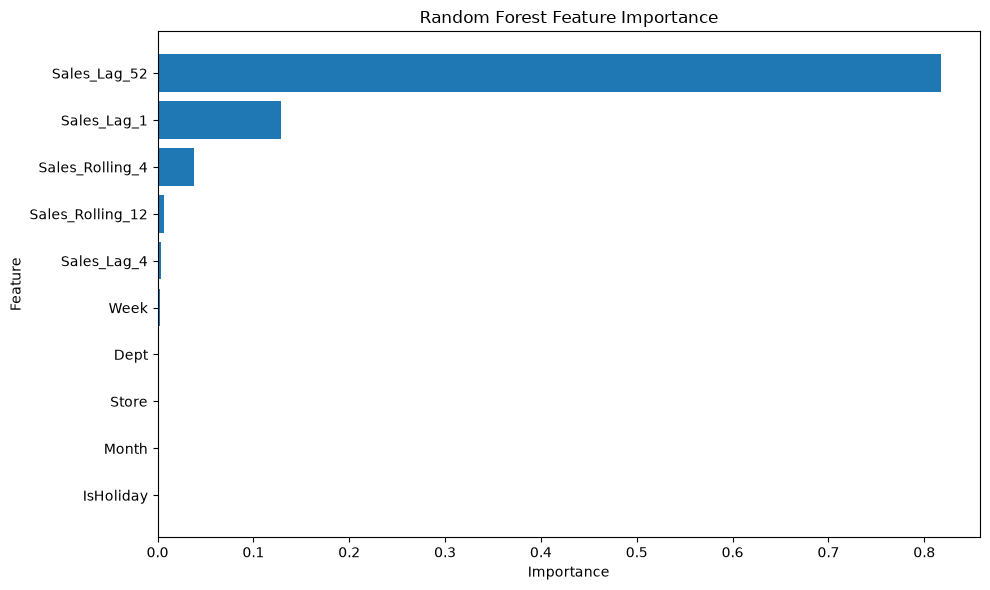

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(10, 6))
plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.gca().invert_yaxis()
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## 9. Compare Actual and Predicted Sales

This plot compares observed weekly sales with Random Forest predictions for the validation period. The scatter plot also includes a 45-degree reference line: points closer to the line indicate more accurate predictions.

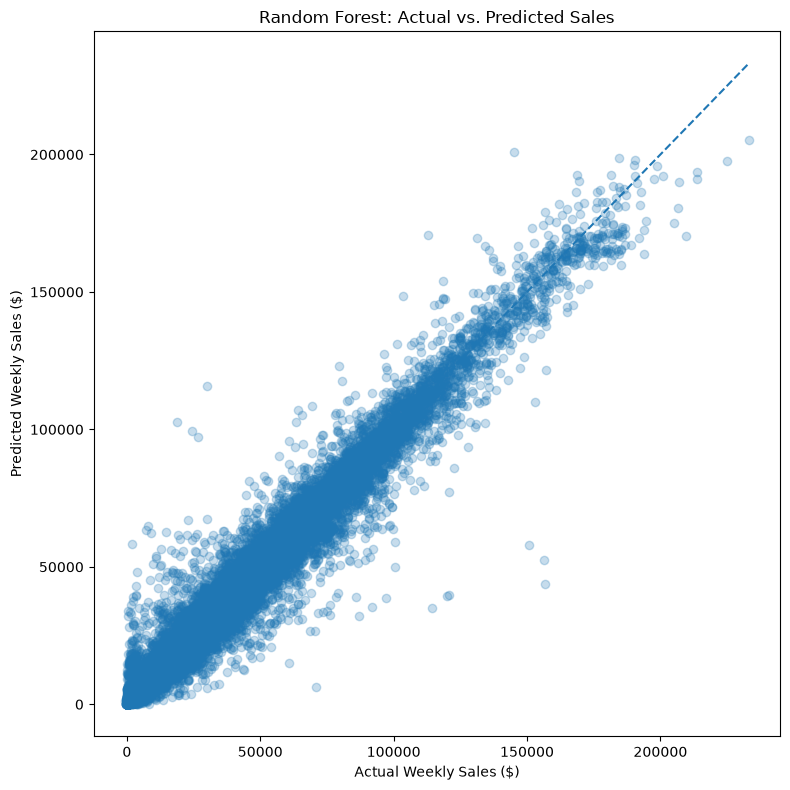

,Store,Dept,Date,Weekly_Sales,Predicted_Sales,Absolute_Error
128193,14,1,2012-04-06,156677.00,43883.932920,112793.067080
187448,20,1,2012-04-06,156234.28,52487.153261,103747.126739
117719,13,1,2012-04-06,150715.44,58125.828406,92589.611594
117721,13,1,2012-04-20,30200.67,115721.306530,85520.636530
128195,14,1,2012-04-20,18877.13,102526.297986,83649.167986
216932,23,1,2012-04-06,120877.00,39823.966737,81053.033263
87637,10,1,2012-04-06,120131.35,39400.684528,80730.665472
118027,13,3,2012-09-07,114230.60,35195.623228,79034.976772
187450,20,1,2012-04-20,24247.26,99353.822261,75106.562261
87639,10,1,2012-04-20,26759.76,97336.283413,70576.523413


In [ ]:
# Actual vs. predicted sales for Random Forest

plt.figure(figsize=(8, 8))
plt.scatter(y_val, rf_predictions, alpha=0.25)
max_value = max(float(y_val.max()), float(np.max(rf_predictions)))
plt.plot([0, max_value], [0, max_value], linestyle="--")
plt.xlabel("Actual Weekly Sales ($)")
plt.ylabel("Predicted Weekly Sales ($)")
plt.title("Random Forest: Actual vs. Predicted Sales")
plt.tight_layout()
plt.show()

# Inspect prediction errors
prediction_results = validation_df[["Store", "Dept", "Date", "Weekly_Sales"]].copy()
prediction_results["Predicted_Sales"] = rf_predictions
prediction_results["Absolute_Error"] = np.abs(
    prediction_results["Weekly_Sales"] - prediction_results["Predicted_Sales"]
)
display(prediction_results.sort_values("Absolute_Error", ascending=False).head(10))


## 10. Analyze Sales During Major Holidays

The following dates are Walmart weekly records associated with major holiday periods. These are weekly observations, not daily holiday sales. The 2012 Thanksgiving and Christmas dates fall outside the dataset's date range, so those records will not appear in the results.

In [ ]:
holiday_dates = {
    "Super Bowl": ["2010-02-12", "2011-02-11", "2012-02-10"],
    "Labor Day": ["2010-09-10", "2011-09-09", "2012-09-07"],
    "Thanksgiving": ["2010-11-26", "2011-11-25", "2012-11-23"],
    "Christmas Peak Reference Week": ["2010-12-24", "2011-12-23", "2012-12-28"]
}

weekly_sales = df.groupby("Date", as_index=False)["Weekly_Sales"].sum()
holiday_results = []
for holiday, date_list in holiday_dates.items():
    for date_string in date_list:
        holiday_date = pd.Timestamp(date_string)
        match = weekly_sales[weekly_sales["Date"] == holiday_date]
        if not match.empty:
            holiday_results.append({
                "Holiday": holiday,
                "Date": holiday_date,
                "Weekly_Sales": match["Weekly_Sales"].iloc[0]
            })

holiday_analysis = pd.DataFrame(holiday_results)
display(holiday_analysis)


,Holiday,Date,Weekly_Sales
0,Super Bowl,2010-02-12,48336677.63
1,Super Bowl,2011-02-11,47336192.79
2,Super Bowl,2012-02-10,50009407.92
3,Labor Day,2010-09-10,45634397.84
4,Labor Day,2011-09-09,46763227.53
5,Labor Day,2012-09-07,48330059.31
6,Thanksgiving,2010-11-26,65821003.24
7,Thanksgiving,2011-11-25,66593605.26
8,Christmas Peak Reference Week,2010-12-24,80931415.60
9,Christmas Peak Reference Week,2011-12-23,76998241.31


## 11. Calculate Holiday Sales Uplift

For each holiday reference week, compare its total sales with the average of the available weekly records within two weeks before and two weeks after it. This is a descriptive comparison. It does not isolate the holiday's causal effect, and surrounding weeks may be influenced by other seasonal factors.

In [ ]:
holiday_uplift = []
for _, row in holiday_analysis.iterrows():
    holiday_date = row["Date"]
    surrounding = weekly_sales[
        (weekly_sales["Date"] >= holiday_date - pd.Timedelta(weeks=2)) &
        (weekly_sales["Date"] <= holiday_date + pd.Timedelta(weeks=2)) &
        (weekly_sales["Date"] != holiday_date)
    ]
    if not surrounding.empty:
        surrounding_average = surrounding["Weekly_Sales"].mean()
        uplift_percent = (row["Weekly_Sales"] - surrounding_average) / surrounding_average * 100
        holiday_uplift.append({
            "Holiday": row["Holiday"],
            "Date": holiday_date,
            "Holiday_Week_Sales": row["Weekly_Sales"],
            "Surrounding_Weeks_Average": surrounding_average,
            "Sales_Uplift_Percent": uplift_percent
        })

holiday_uplift_df = pd.DataFrame(holiday_uplift)
display(holiday_uplift_df.round(2))


/var/folders/nl/w9g5lm9578s_6p8xpc6g_ph00000gn/T/ipykernel_19948/1992298137.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(holiday_uplift_df.round(2))


,Holiday,Date,Holiday_Week_Sales,Surrounding_Weeks_Average,Sales_Uplift_Percent
0,Super Bowl,2010-02-12,48336677.63,47332101.80,2.12
1,Super Bowl,2011-02-11,47336192.79,44648747.02,6.02
2,Super Bowl,2012-02-10,50009407.92,45472286.57,9.98
3,Labor Day,2010-09-10,45634397.84,44385809.74,2.81
4,Labor Day,2011-09-09,46763227.53,44826407.13,4.32
5,Labor Day,2012-09-07,48330059.31,45796887.20,5.53
6,Thanksgiving,2010-11-26,65821003.24,49206545.82,33.76
7,Thanksgiving,2011-11-25,66593605.26,49966227.38,33.28
8,Christmas Peak Reference Week,2010-12-24,80931415.60,50173969.25,61.30
9,Christmas Peak Reference Week,2011-12-23,76998241.31,51661181.66,49.04


## 12. Analyze Christmas Sales Timing

The dates below are selected Friday-based Christmas peak reference weeks in the dataset, not Christmas Day itself. The 2012 reference date is outside the dataset's coverage, so no 2012 Christmas sales rows are expected.

In [ ]:
christmas_reference_dates = {
    2010: pd.Timestamp("2010-12-24"),
    2011: pd.Timestamp("2011-12-23"),
    2012: pd.Timestamp("2012-12-28")
}

christmas_results = []
for year, reference_date in christmas_reference_dates.items():
    for week_offset in [-2, -1, 0, 1, 2]:
        target_date = reference_date + pd.Timedelta(weeks=week_offset)
        match = weekly_sales[weekly_sales["Date"] == target_date]
        if not match.empty:
            christmas_results.append({
                "Year": year,
                "Week_Offset": week_offset,
                "Date": target_date,
                "Weekly_Sales": match["Weekly_Sales"].iloc[0]
            })

christmas_analysis = pd.DataFrame(christmas_results)
display(christmas_analysis)


,Year,Week_Offset,Date,Weekly_Sales
0,2010,-2,2010-12-10,55666770.39
1,2010,-1,2010-12-17,61820799.85
2,2010,0,2010-12-24,80931415.60
3,2010,1,2010-12-31,40432519.00
4,2010,2,2011-01-07,42775787.77
5,2011,-2,2011-12-09,55561147.70
6,2011,-1,2011-12-16,60085695.94
7,2011,0,2011-12-23,76998241.31
8,2011,1,2011-12-30,46042461.04
9,2011,2,2012-01-06,44955421.95


## 13. Create Christmas Timing Features

`Weeks_To_Christmas_Reference_Week` is positive before the selected reference week, zero on the reference week, and negative afterward. This is a calendar feature based on the selected weekly peak reference dates, not the exact date of Christmas Day.

`Christmas_Period` flags the four weeks leading up to and including the reference week. Because the 2012 Christmas reference week is outside the dataset, its usefulness cannot be validated using this dataset's 2012 holdout.

In [ ]:
christmas_reference_dates = {
    2010: pd.Timestamp("2010-12-24"),
    2011: pd.Timestamp("2011-12-23"),
    2012: pd.Timestamp("2012-12-28")
}

df["Christmas_Reference_Week"] = df["Year"].map(christmas_reference_dates)
days_to_reference = (df["Christmas_Reference_Week"] - df["Date"]).dt.days
# Walmart dates are weekly observations. Use integer weekly offsets.
df["Weeks_To_Christmas_Reference_Week"] = (days_to_reference / 7).round().astype("Int64")
df["Christmas_Period"] = df["Weeks_To_Christmas_Reference_Week"].between(0, 4).astype(int)

display(df[[
    "Date", "Year", "Weeks_To_Christmas_Reference_Week", "Christmas_Period"
]].tail(15))


,Date,Year,Weeks_To_Christmas_Reference_Week,Christmas_Period
421555,2012-07-20,2012,23,0
421556,2012-07-27,2012,22,0
421557,2012-08-03,2012,21,0
421558,2012-08-10,2012,20,0
421559,2012-08-17,2012,19,0
421560,2012-08-24,2012,18,0
421561,2012-08-31,2012,17,0
421562,2012-09-07,2012,16,0
421563,2012-09-14,2012,15,0
421564,2012-09-21,2012,14,0


## 14. Project Findings and Interpretation

### Key findings to complete after running the notebook

- Exploratory analysis identified differences in weekly sales across store types, departments, seasonal periods, and holidays.

- Historical sales features improved forecasting performance compared with the seasonal naive benchmark.

- Random Forest achieved the best forecasting performance, with an MAE of $1,394.19 and RMSE of $3,103.01.

- LightGBM achieved an MAE of $1,479.31 and RMSE of $3,358.93.

- The Seasonal Naive model achieved an MAE of $1,817.35 and RMSE of $3,842.39.

- The 52-week sales lag was the most important feature in the Random Forest model, indicating that previous-year sales patterns were highly predictive.

- Holiday and Christmas analyses identified changes in weekly sales around major shopping periods. These findings are descriptive and do not establish causation.

### Model Performance Comparison
Random Forest: MAE $1,394.19, RMSE $3,103.01



LightGBM: MAE $1,479.31, RMSE $3,358.93



Seasonal Naive: MAE $1,817.35, RMSE $3,842.39


### Inventory intelligence scope

The dataset does not contain actual inventory levels, stockouts, replenishment records, or product availability. Therefore, this project cannot directly measure stockout rates, inventory efficiency, or inventory cost savings.

Forecasted sales could support future inventory planning through assumption-based reorder recommendations. These recommendations would require additional inventory data and should be evaluated separately.

## 15. Limitations and Next Improvements

1. **Single holdout period:** Add rolling-origin backtesting across multiple cutoff dates.
2. **One-week-ahead setup:** Multi-week forecasting requires recursive predictions or a direct multi-horizon approach.
3. **Historical sales coverage:** Lag features remove early observations that lack sufficient history.
4. **Holiday interpretation:** The surrounding-week uplift is descriptive and may be affected by seasonal trends.
5. **Inventory data gap:** Actual inventory and stockout data are unavailable.
6. **Model tuning:** Try validation-based hyperparameter tuning without using the final test set.
7. **External test set:** Once model selection is complete, prepare predictions for the competition test dataset without using its target values.

## 16. Conclusion

This notebook builds an end-to-end Walmart weekly sales analysis and forecasting workflow using PostgreSQL and Python. It explores sales patterns, creates leakage-aware historical features, trains Random Forest and LightGBM models, and compares forecasts against a seasonal naive benchmark.

The final reported model should be selected using the same validation rows and metrics. The next portfolio step is to build a Power BI dashboard with sales trends, store/department comparisons, holiday analysis, and forecast-versus-actual results.